In [4]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files
import zipfile

print("OpenCV:", cv2.__version__)

BASE_DIR = Path("ECG_Preprocessing_Project")
RAW_DIR = BASE_DIR / "raw"
OUT_DIR = BASE_DIR / "processed"
PREVIEW_DIR = BASE_DIR / "preview"

for folder in [RAW_DIR, OUT_DIR, PREVIEW_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders are ready.")

OpenCV: 4.14.0
Project folders are ready.


In [5]:
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("কোনো ছবি Upload করা হয়নি। আবার Run করে ECG ছবিগুলো নির্বাচন করো।")

print(f"\nTotal uploaded files: {len(uploaded)}")
for filename in uploaded.keys():
    print("-", filename)

Saving WhatsApp Image 2026-11-03 at 4.29.42 PM.jpeg to WhatsApp Image 2026-11-03 at 4.29.42 PM (1).jpeg
Saving WhatsApp Image 2026-11-03 at 4.29.41 PM.jpeg to WhatsApp Image 2026-11-03 at 4.29.41 PM (1).jpeg

Total uploaded files: 2
- WhatsApp Image 2026-11-03 at 4.29.42 PM (1).jpeg
- WhatsApp Image 2026-11-03 at 4.29.41 PM (1).jpeg


In [6]:
images = {}

for filename, file_bytes in uploaded.items():
    if not filename.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")):
        print(f"Skipped unsupported file: {filename}")
        continue

    arr = np.frombuffer(file_bytes, dtype=np.uint8)
    image = cv2.imdecode(arr, cv2.IMREAD_COLOR)

    if image is None:
        print(f"Could not decode: {filename}")
        continue

    images[filename] = image
    (RAW_DIR / filename).write_bytes(file_bytes)

    h, w = image.shape[:2]
    print(f"{filename}: width={w}, height={h}, channels={image.shape[2]}")

if len(images) == 0:
    raise RuntimeError("কোনো valid image পাওয়া যায়নি।")

WhatsApp Image 2026-11-03 at 4.29.42 PM (1).jpeg: width=1599, height=1084, channels=3
WhatsApp Image 2026-11-03 at 4.29.41 PM (1).jpeg: width=1600, height=1101, channels=3


In [7]:
def order_points(points):
    """চারটি point-কে top-left, top-right, bottom-right, bottom-left ক্রমে সাজায়."""
    pts = np.asarray(points, dtype="float32")
    s = pts.sum(axis=1)
    diff = np.diff(pts, axis=1).reshape(-1)

    return np.array([
        pts[np.argmin(s)],       # top-left
        pts[np.argmin(diff)],    # top-right
        pts[np.argmax(s)],       # bottom-right
        pts[np.argmax(diff)]     # bottom-left
    ], dtype="float32")


def find_paper_corners(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    _, binary = cv2.threshold(
        blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (21, 21))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=2)
    contours, _ = cv2.findContours(
        closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    image_area = image.shape[0] * image.shape[1]
    contours = sorted(contours, key=cv2.contourArea, reverse=True)

    for contour in contours:
        area = cv2.contourArea(contour)
        if area < 0.20 * image_area or area > 0.98 * image_area:
            continue

        perimeter = cv2.arcLength(contour, True)
        approx = cv2.approxPolyDP(contour, 0.02 * perimeter, True)

        if len(approx) == 4:
            return order_points(approx.reshape(4, 2))

    return None


def perspective_correct(image):
    corners = find_paper_corners(image)

    if corners is None:
        print("Paper corners not detected; using original framing.")
        return image.copy(), False

    tl, tr, br, bl = corners
    width_a = np.linalg.norm(br - bl)
    width_b = np.linalg.norm(tr - tl)
    height_a = np.linalg.norm(tr - br)
    height_b = np.linalg.norm(tl - bl)

    width = max(1, int(max(width_a, width_b)))
    height = max(1, int(max(height_a, height_b)))

    destination = np.array([
        [0, 0],
        [width - 1, 0],
        [width - 1, height - 1],
        [0, height - 1]
    ], dtype="float32")

    matrix = cv2.getPerspectiveTransform(corners, destination)
    warped = cv2.warpPerspective(
        image, matrix, (width, height),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE
    )
    return warped, True

In [8]:
def preprocess_ecg_image(color_image):
    gray = cv2.cvtColor(color_image, cv2.COLOR_BGR2GRAY)

    # Mild denoising: preserve thin ECG waveform as much as possible
    denoised = cv2.fastNlMeansDenoising(
        gray, None, h=7, templateWindowSize=7, searchWindowSize=21
    )

    # Local contrast enhancement
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    enhanced = clahe.apply(denoised)

    return gray, denoised, enhanced

In [9]:
MASK_PATIENT_INFO = True  # দরকার না হলে False করো


def mask_patient_info(image):
    if not MASK_PATIENT_INFO:
        return image.copy()

    result = image.copy()
    h, w = result.shape[:2]

    # Approximate top-left patient ID/name/demographic block
    x1, y1 = int(0.04 * w), int(0.02 * h)
    x2, y2 = int(0.23 * w), int(0.16 * h)
    cv2.rectangle(result, (x1, y1), (x2, y2), (255, 255, 255), -1)

    # Approximate printed date/time block near the upper middle
    x1, y1 = int(0.28 * w), int(0.015 * h)
    x2, y2 = int(0.50 * w), int(0.065 * h)
    cv2.rectangle(result, (x1, y1), (x2, y2), (255, 255, 255), -1)

    return result

In [10]:
processed_results = {}
summary_rows = []

for index, (filename, original) in enumerate(images.items(), start=1):
    print(f"Processing {index}/{len(images)}: {filename}")

    rectified_color, paper_detected = perspective_correct(original)
    gray, denoised, enhanced_gray = preprocess_ecg_image(rectified_color)

    # Mask identifiers only on the shareable/output copy
    sanitized_color = mask_patient_info(rectified_color)
    sanitized_gray = mask_patient_info(enhanced_gray)

    # Safe output names
    stem = Path(filename).stem
    safe_stem = f"ECG_{index:02d}_{stem[:30]}"

    color_path = OUT_DIR / f"{safe_stem}_rectified_color.png"
    gray_path = OUT_DIR / f"{safe_stem}_preprocessed_gray.png"
    denoise_path = OUT_DIR / f"{safe_stem}_denoised_gray.png"

    cv2.imwrite(str(color_path), sanitized_color)
    cv2.imwrite(str(gray_path), sanitized_gray)
    cv2.imwrite(str(denoise_path), denoised)

    processed_results[filename] = {
        "original": original,
        "rectified": sanitized_color,
        "gray": sanitized_gray,
        "denoised": denoised,
        "enhanced": enhanced_gray,
        "paper_detected": paper_detected,
        "color_path": color_path,
        "gray_path": gray_path
    }

    oh, ow = original.shape[:2]
    ph, pw = rectified_color.shape[:2]
    summary_rows.append({
        "input_file": filename,
        "original_width": ow,
        "original_height": oh,
        "processed_width": pw,
        "processed_height": ph,
        "paper_boundary_detected": paper_detected,
        "grayscale": True,
        "mild_denoising": True,
        "clahe_contrast_enhancement": True,
        "patient_info_masking": MASK_PATIENT_INFO
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

Processing 1/2: WhatsApp Image 2026-11-03 at 4.29.42 PM (1).jpeg
Processing 2/2: WhatsApp Image 2026-11-03 at 4.29.41 PM (1).jpeg


,input_file,original_width,original_height,processed_width,processed_height,paper_boundary_detected,grayscale,mild_denoising,clahe_contrast_enhancement,patient_info_masking
0,WhatsApp Image 2026-11-03 at 4.29.42 PM (1).jpeg,1599,1084,1356,958,True,True,True,True,True
1,WhatsApp Image 2026-11-03 at 4.29.41 PM (1).jpeg,1600,1101,1437,986,True,True,True,True,True


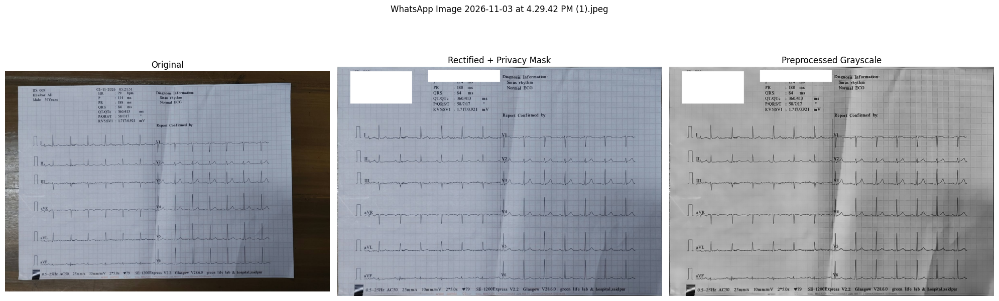

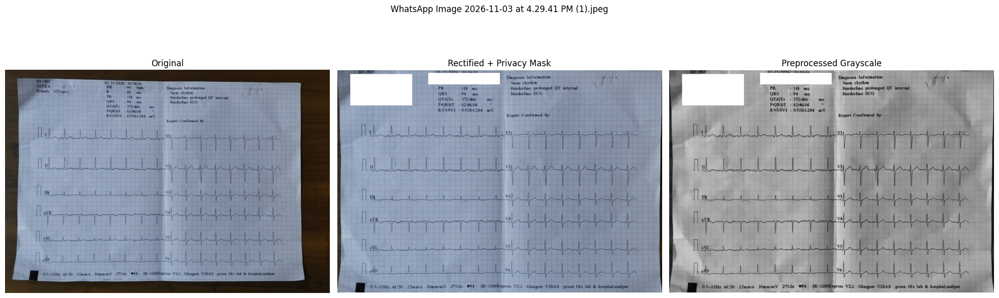

In [11]:
for filename, result in processed_results.items():
    original_rgb = cv2.cvtColor(result["original"], cv2.COLOR_BGR2RGB)
    processed_rgb = cv2.cvtColor(result["rectified"], cv2.COLOR_BGR2RGB)
    gray = result["gray"]

    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    axes[0].imshow(original_rgb)
    axes[0].set_title("Original")
    axes[1].imshow(processed_rgb)
    axes[1].set_title("Rectified + Privacy Mask")
    axes[2].imshow(gray, cmap="gray")
    axes[2].set_title("Preprocessed Grayscale")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

In [12]:
# Cell 1: Import libraries
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.ndimage import median_filter
from scipy.signal import butter, sosfiltfilt, savgol_filter
from google.colab import files
from IPython.display import display

print("Libraries imported successfully")
print("OpenCV:", cv2.__version__)

Libraries imported successfully
OpenCV: 4.14.0


In [13]:
# Cell 2: Upload the TWO ORIGINAL ECG photos
# Keep the original filenames unchanged so the correct image settings are selected.

uploaded = files.upload()

if len(uploaded) != 2:
    raise ValueError(f"Expected 2 ECG images, but received {len(uploaded)}. Please upload both original photos.")

print("Uploaded files:")
for name in uploaded:
    print(" -", name)

Saving WhatsApp Image 2026-11-03 at 4.29.42 PM.jpeg to WhatsApp Image 2026-11-03 at 4.29.42 PM (2).jpeg
Saving WhatsApp Image 2026-11-03 at 4.29.41 PM.jpeg to WhatsApp Image 2026-11-03 at 4.29.41 PM (2).jpeg
Uploaded files:
 - WhatsApp Image 2026-11-03 at 4.29.42 PM (2).jpeg
 - WhatsApp Image 2026-11-03 at 4.29.41 PM (2).jpeg


In [15]:
# Cell 3: Image-specific settings
# These corner points and row baselines are calibrated for the two photos you sent.
# If you later use different photos, these coordinates MUST be recalibrated.

CANVAS_WIDTH = 1300
CANVAS_HEIGHT = 920

# ECG print settings read from the report footer:
PAPER_SPEED_MM_PER_SEC = 25.0
GAIN_MM_PER_MV = 10.0

# Approximate pixel calibration after perspective correction.
# You can refine this by measuring the 10-mm calibration pulse or grid spacing.
PIXELS_PER_MM = 4.4

# Waveform extraction settings (adjust if the red extraction overlay does not follow the black ECG line)
DARK_PIXEL_THRESHOLD = 100   # lower = stricter; higher = detects fainter trace and more grid/noise
ROW_HALF_HEIGHT = 50

# IMPORTANT: file-name keys identify which coordinate set belongs to which photo.
IMAGE_CONFIGS = {
    "4.29.41": {
        "record_id": "ECG_1",
        "corners": [[56, 38], [1357, 60], [1370, 964], [34, 955]],  # TL, TR, BR, BL in original photo
        "row_baselines": [292, 440, 570, 670, 780, 888],
    },
    "4.29.42": {
        "record_id": "ECG_2",
        "corners": [[60, 56], [1326, 54], [1335, 956], [61, 957]],
        "row_baselines": [310, 420, 510, 642, 777, 905],
    },
}

# Each row contains one left-side lead and one right-side lead.
LEFT_LEADS = ["I", "II", "III", "aVR", "aVL", "aVF"]
RIGHT_LEADS = ["V1", "V2", "V3", "V4", "V5", "V6"]

# These portions of the supplied photos need extra manual inspection due to shadow/edge quality.
KNOWN_REVIEW_LEADS = {
    ("ECG_1", "aVF"), ("ECG_1", "V6"),
    ("ECG_2", "II"), ("ECG_2", "aVF"),
    ("ECG_2", "V4"), ("ECG_2", "V5"), ("ECG_2", "V6"),
}

# Start after the printed lead labels; end near the end of the visible waveform.
LEFT_X_RANGE = (180, 695)
RIGHT_X_RANGE = (750, 1270)

OUTPUT_DIR = Path("ECG_Graph_Data_Processing")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Settings ready. Pixel-to-voltage scaling is approximate:", PIXELS_PER_MM, "px/mm")

Settings ready. Pixel-to-voltage scaling is approximate: 4.4 px/mm


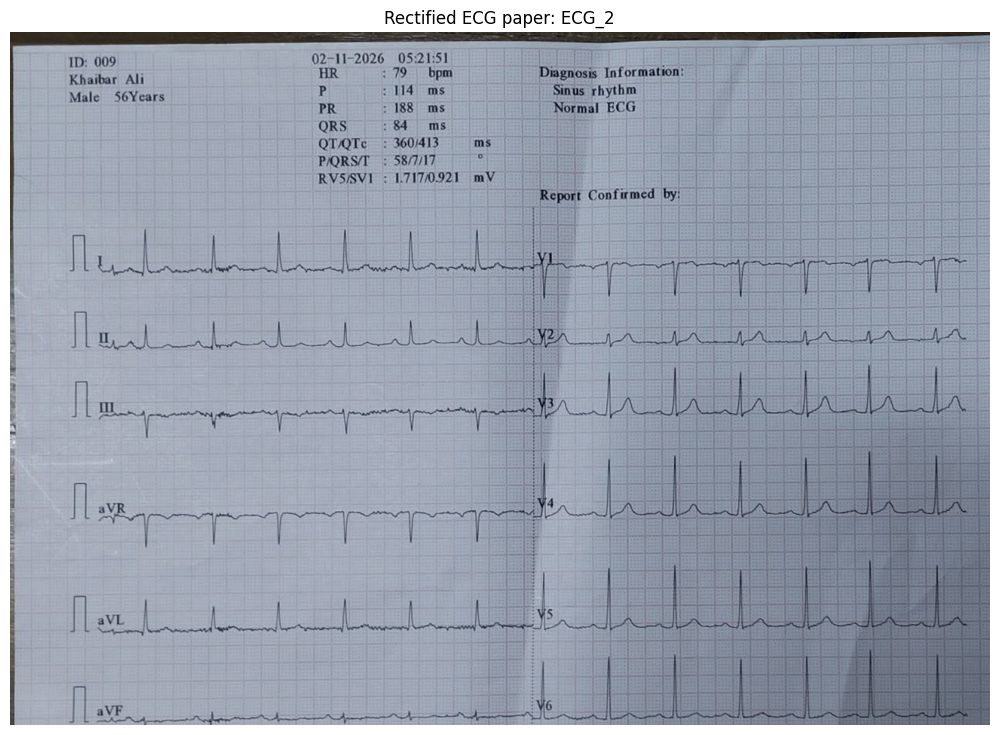

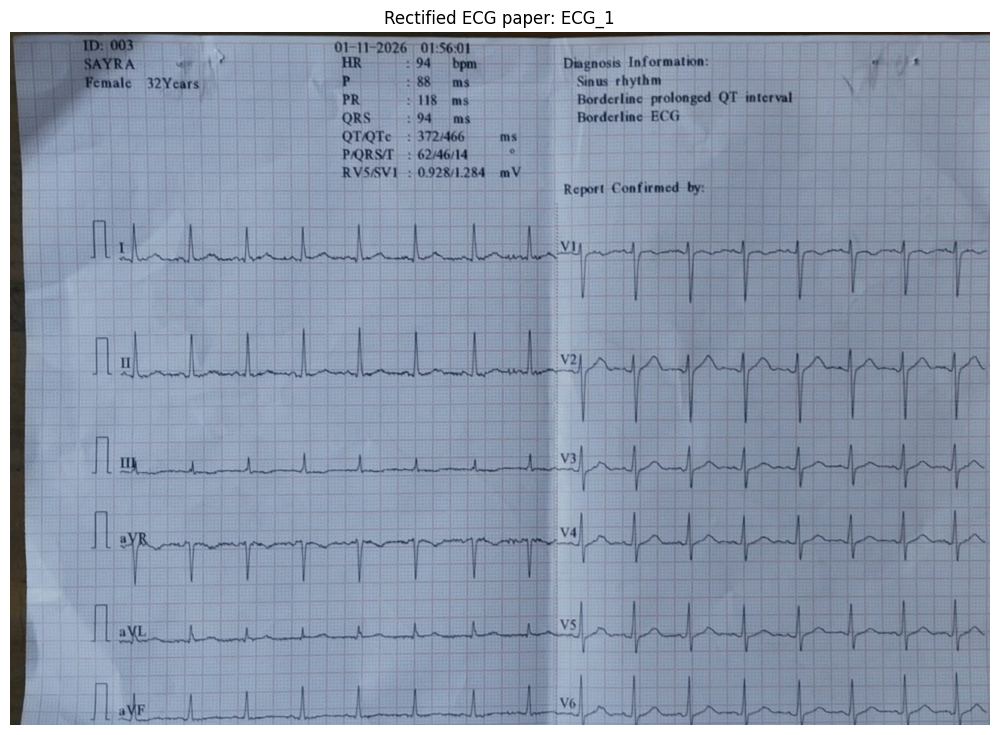

Perspective correction completed for 2 images


In [16]:
# Cell 4: Correct perspective and display the rectified paper

rectified_images = {}
configs_used = {}

dst_points = np.float32([
    [0, 0],
    [CANVAS_WIDTH - 1, 0],
    [CANVAS_WIDTH - 1, CANVAS_HEIGHT - 1],
    [0, CANVAS_HEIGHT - 1],
])

for filename, file_bytes in uploaded.items():
    matching_key = next((key for key in IMAGE_CONFIGS if key in filename), None)
    if matching_key is None:
        raise ValueError(
            f"Could not match '{filename}' to the supplied image settings. "
            "Please upload the original filenames containing 4.29.41 or 4.29.42."
        )

    cfg = IMAGE_CONFIGS[matching_key]
    image_array = np.frombuffer(file_bytes, dtype=np.uint8)
    original = cv2.imdecode(image_array, cv2.IMREAD_COLOR)
    if original is None:
        raise ValueError(f"Could not decode image: {filename}")

    src_points = np.float32(cfg["corners"])
    H = cv2.getPerspectiveTransform(src_points, dst_points)
    rectified = cv2.warpPerspective(
        original, H, (CANVAS_WIDTH, CANVAS_HEIGHT),
        flags=cv2.INTER_CUBIC
    )

    rectified_images[cfg["record_id"]] = rectified
    configs_used[cfg["record_id"]] = cfg

    plt.figure(figsize=(16, 9))
    plt.imshow(cv2.cvtColor(rectified, cv2.COLOR_BGR2RGB))
    plt.title(f"Rectified ECG paper: {cfg['record_id']}")
    plt.axis("off")
    plt.show()

print("Perspective correction completed for", len(rectified_images), "images")

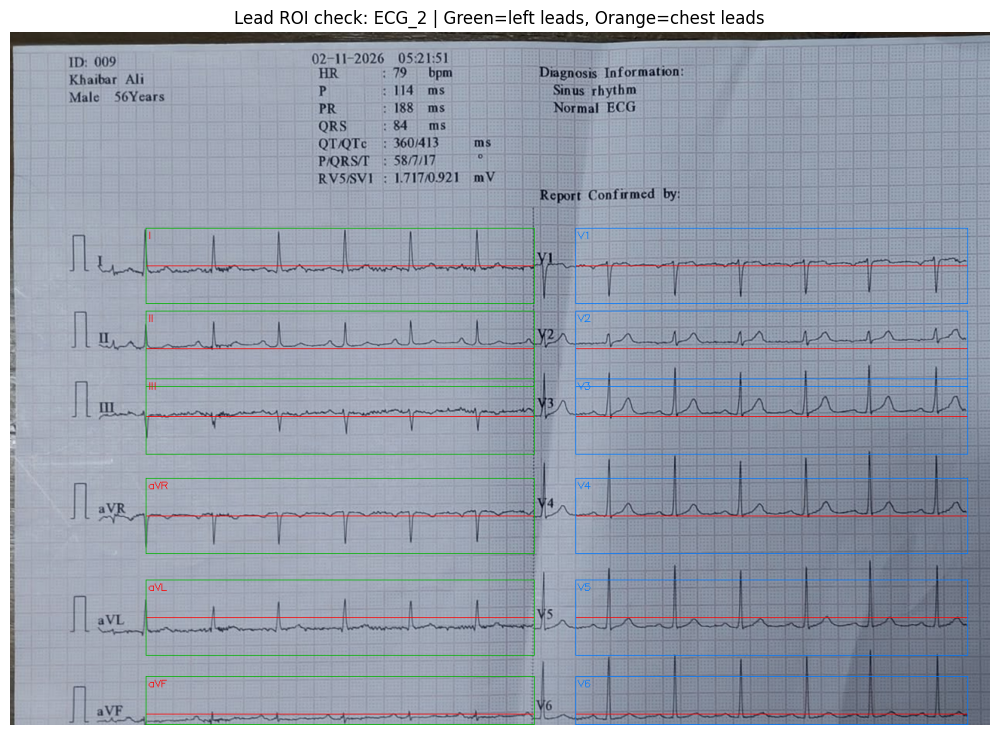

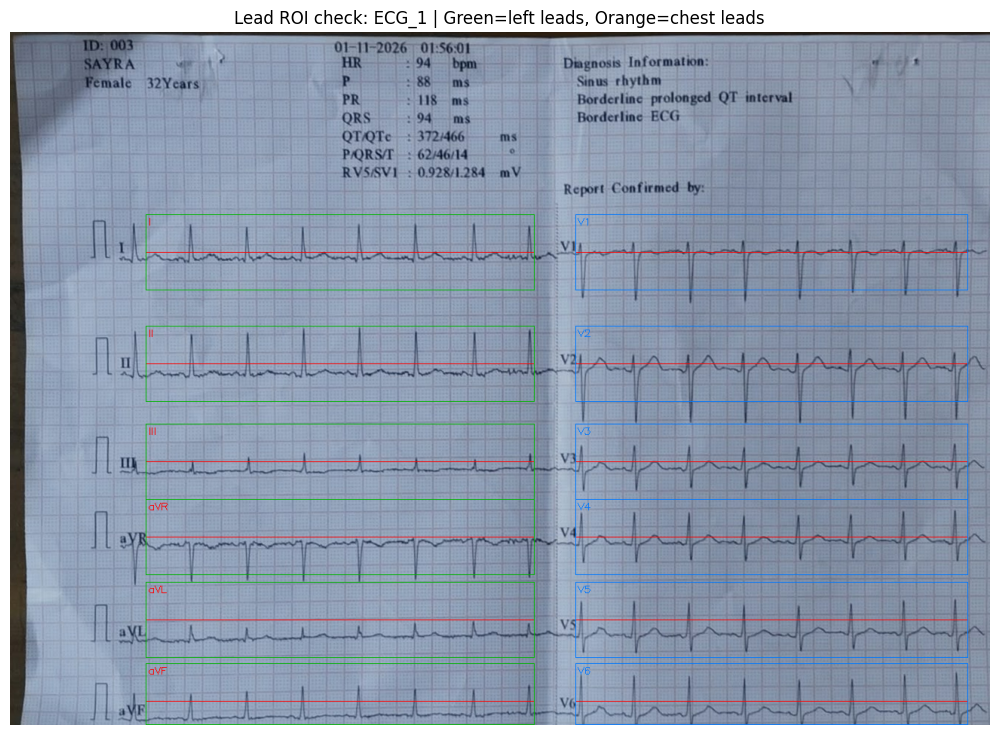

In [17]:
# Cell 5: Visualize the 12 lead regions before extracting data

for record_id, image in rectified_images.items():
    cfg = configs_used[record_id]
    preview = image.copy()

    # Draw row baselines and lead-region boundaries
    for row_idx, baseline in enumerate(cfg["row_baselines"]):
        cv2.line(preview, (LEFT_X_RANGE[0], baseline), (LEFT_X_RANGE[1], baseline), (0, 0, 255), 1)
        cv2.line(preview, (RIGHT_X_RANGE[0], baseline), (RIGHT_X_RANGE[1], baseline), (0, 0, 255), 1)
        cv2.rectangle(preview,
                      (LEFT_X_RANGE[0], max(0, baseline - ROW_HALF_HEIGHT)),
                      (LEFT_X_RANGE[1], min(CANVAS_HEIGHT - 1, baseline + ROW_HALF_HEIGHT)),
                      (0, 180, 0), 1)
        cv2.rectangle(preview,
                      (RIGHT_X_RANGE[0], max(0, baseline - ROW_HALF_HEIGHT)),
                      (RIGHT_X_RANGE[1], min(CANVAS_HEIGHT - 1, baseline + ROW_HALF_HEIGHT)),
                      (255, 120, 0), 1)
        cv2.putText(preview, LEFT_LEADS[row_idx], (LEFT_X_RANGE[0] + 3, baseline - ROW_HALF_HEIGHT + 14),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1)
        cv2.putText(preview, RIGHT_LEADS[row_idx], (RIGHT_X_RANGE[0] + 3, baseline - ROW_HALF_HEIGHT + 14),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 120, 0), 1)

    plt.figure(figsize=(16, 9))
    plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
    plt.title(f"Lead ROI check: {record_id} | Green=left leads, Orange=chest leads")
    plt.axis("off")
    plt.show()

In [18]:
# Cell 6: Extract a waveform from one lead ROI

def extract_trace_from_roi(gray_image, baseline_y, x_start, x_end,
                           threshold=100, half_height=50):
    """Extract approximate ECG centerline y-coordinate, one value per image column."""
    height, width = gray_image.shape
    x_start = max(0, int(x_start))
    x_end = min(width, int(x_end))
    y_start = max(0, int(baseline_y - half_height))
    y_end = min(height, int(baseline_y + half_height))

    roi = gray_image[y_start:y_end, x_start:x_end]
    if roi.size == 0 or roi.shape[1] < 20:
        raise ValueError("Empty or too-small lead ROI. Check crop coordinates.")

    # Infer the dominant QRS direction from the first 80% of the trace.
    # This helps reject some dark grid/shadow pixels on the opposite side of baseline.
    up_extent, down_extent = [], []
    for col in range(max(1, int(0.80 * roi.shape[1]))):
        yy = np.flatnonzero(roi[:, col] < threshold) + y_start
        if yy.size:
            up_extent.append(max(0.0, float(baseline_y - yy.min())))
            down_extent.append(max(0.0, float(yy.max() - baseline_y)))

    up_strength = float(np.percentile(up_extent, 98)) if up_extent else 0.0
    down_strength = float(np.percentile(down_extent, 98)) if down_extent else 0.0
    if up_strength > 1.3 * down_strength and up_strength > 12:
        polarity = "predominantly_positive"
        up_limit, down_limit = half_height, min(25, half_height)
    elif down_strength > 1.3 * up_strength and down_strength > 12:
        polarity = "predominantly_negative"
        up_limit, down_limit = min(25, half_height), half_height
    else:
        polarity = "mixed_or_uncertain"
        up_limit = down_limit = half_height

    trace_y = np.full(roi.shape[1], np.nan, dtype=float)
    for col in range(roi.shape[1]):
        candidate_y = np.flatnonzero(roi[:, col] < threshold) + y_start
        candidate_y = candidate_y[
            (candidate_y >= baseline_y - up_limit) &
            (candidate_y <= baseline_y + down_limit)
        ]
        if candidate_y.size == 1:
            trace_y[col] = float(candidate_y[0])
        elif candidate_y.size > 1:
            trace_y[col] = float(candidate_y[np.argmax(np.abs(candidate_y - baseline_y))])

    valid = np.isfinite(trace_y)
    missing_fraction = 1.0 - valid.mean()
    if valid.sum() < max(20, int(0.30 * len(trace_y))):
        raise ValueError(
            "Too few waveform pixels detected. Decrease/Increase DARK_PIXEL_THRESHOLD or adjust the ROI."
        )

    # Interpolate missed columns; keep missing_fraction so low-confidence leads can be reviewed.
    x = np.arange(len(trace_y))
    trace_y[~valid] = np.interp(x[~valid], x[valid], trace_y[valid])

    # Very light smoothing to suppress isolated pixel jitter while retaining QRS peaks.
    trace_y = median_filter(trace_y, size=3)
    if len(trace_y) >= 7:
        trace_y = savgol_filter(trace_y, window_length=7, polyorder=2)

    return trace_y, missing_fraction, x_start, y_start, polarity

print("Waveform extraction function is ready")

Waveform extraction function is ready


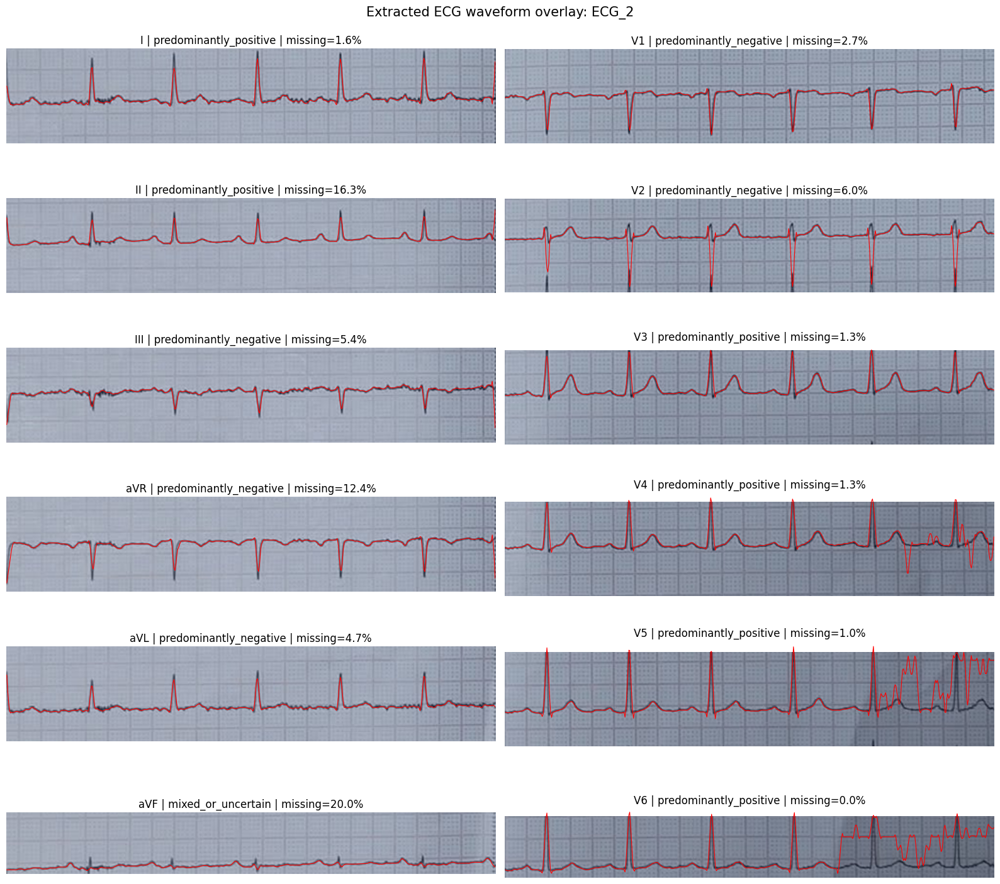

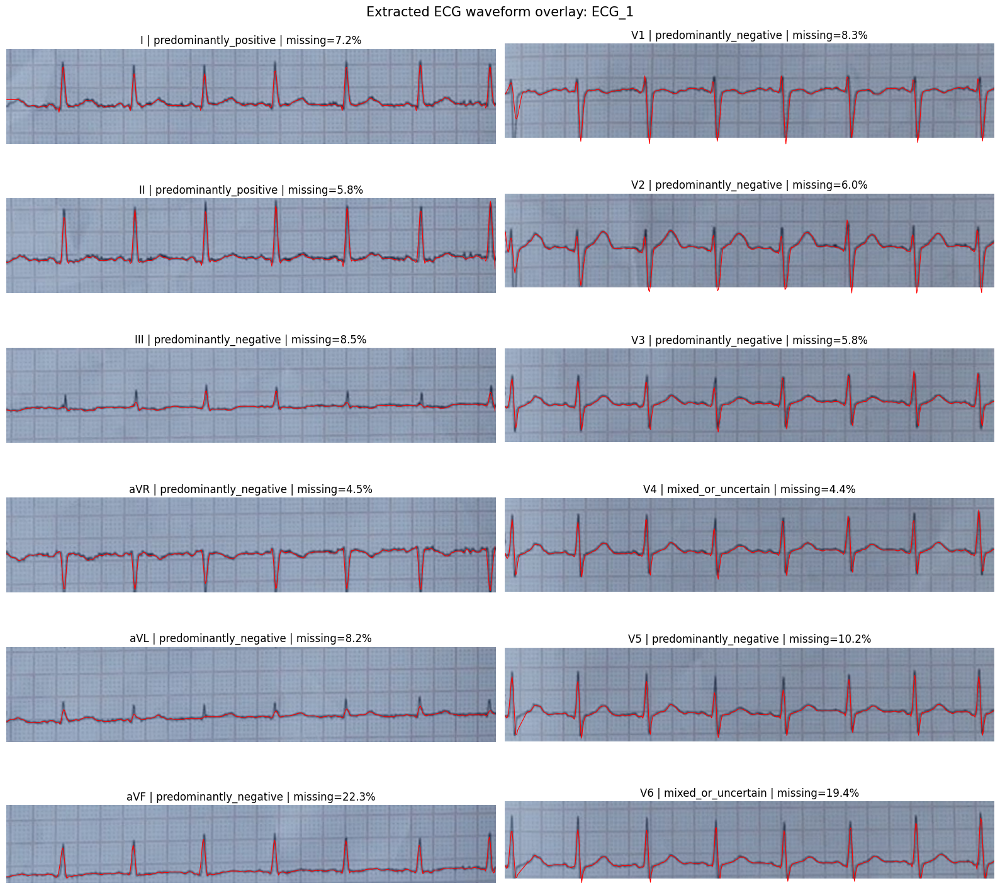

Extracted leads: 24


,record_id,lead,samples,estimated_sampling_rate_hz,estimated_duration_s,pixels_per_mm,missing_pixel_fraction,inferred_polarity,quality_flag
0,ECG_2,I,515,110.0,4.682,4.4,0.0155,predominantly_positive,VISUAL_CHECK_REQUIRED
1,ECG_2,V1,520,110.0,4.727,4.4,0.0269,predominantly_negative,VISUAL_CHECK_REQUIRED
2,ECG_2,II,515,110.0,4.682,4.4,0.1631,predominantly_positive,REVIEW
3,ECG_2,V2,520,110.0,4.727,4.4,0.0596,predominantly_negative,VISUAL_CHECK_REQUIRED
4,ECG_2,III,515,110.0,4.682,4.4,0.0544,predominantly_negative,VISUAL_CHECK_REQUIRED
5,ECG_2,V3,520,110.0,4.727,4.4,0.0135,predominantly_positive,VISUAL_CHECK_REQUIRED
6,ECG_2,aVR,515,110.0,4.682,4.4,0.1243,predominantly_negative,VISUAL_CHECK_REQUIRED
7,ECG_2,V4,520,110.0,4.727,4.4,0.0135,predominantly_positive,REVIEW
8,ECG_2,aVL,515,110.0,4.682,4.4,0.0466,predominantly_negative,VISUAL_CHECK_REQUIRED
9,ECG_2,V5,520,110.0,4.727,4.4,0.0096,predominantly_positive,REVIEW


In [19]:
# Cell 7: Extract all 12 leads and convert pixels to approximate mV/time values

all_signal_frames = []
summary_rows = []
extracted = {}
overlay_paths = []

# Approximate sampling frequency: horizontal image pixels per second.
ESTIMATED_FS = PIXELS_PER_MM * PAPER_SPEED_MM_PER_SEC

for record_id, color_image in rectified_images.items():
    cfg = configs_used[record_id]
    gray = cv2.cvtColor(color_image, cv2.COLOR_BGR2GRAY)
    extracted[record_id] = {}

    fig, axes = plt.subplots(6, 2, figsize=(16, 15))

    for row_idx, baseline_y in enumerate(cfg["row_baselines"]):
        for col_idx, (lead_name, x_range) in enumerate([
            (LEFT_LEADS[row_idx], LEFT_X_RANGE),
            (RIGHT_LEADS[row_idx], RIGHT_X_RANGE),
        ]):
            x_start, x_end = x_range
            trace_y, missing_fraction, used_x_start, used_y_start, inferred_polarity = extract_trace_from_roi(
                gray,
                baseline_y=baseline_y,
                x_start=x_start,
                x_end=x_end,
                threshold=DARK_PIXEL_THRESHOLD,
                half_height=ROW_HALF_HEIGHT,
            )

            # Pixel y increases downward, so upward ECG deflection is positive voltage.
            voltage_raw_mV = (baseline_y - trace_y) / PIXELS_PER_MM / GAIN_MM_PER_MV
            # Correct a small residual offset from manual baseline placement.
            voltage_raw_mV = voltage_raw_mV - np.median(voltage_raw_mV)

            # Mild smoothing followed by a 0.5-25 Hz band-pass filter.
            # The ECG report itself indicates a 0.5-25 Hz display filter.
            if len(voltage_raw_mV) > 40:
                sos = butter(
                    2, [0.5, 25.0], btype="bandpass",
                    fs=ESTIMATED_FS, output="sos"
                )
                voltage_filtered_mV = sosfiltfilt(sos, voltage_raw_mV)
            else:
                voltage_filtered_mV = voltage_raw_mV.copy()

            std_value = np.std(voltage_filtered_mV)
            if std_value > 1e-8:
                voltage_zscore = (voltage_filtered_mV - np.mean(voltage_filtered_mV)) / std_value
            else:
                voltage_zscore = np.zeros_like(voltage_filtered_mV)

            time_s = np.arange(len(trace_y), dtype=float) / ESTIMATED_FS
            duration_s = float(time_s[-1] + 1.0 / ESTIMATED_FS) if len(time_s) else 0.0

            extracted[record_id][lead_name] = {
                "time_s": time_s,
                "trace_y": trace_y,
                "raw_mV": voltage_raw_mV,
                "filtered_mV": voltage_filtered_mV,
                "zscore": voltage_zscore,
                "missing_fraction": missing_fraction,
                "inferred_polarity": inferred_polarity,
            }

            frame = pd.DataFrame({
                "record_id": record_id,
                "lead": lead_name,
                "sample_index": np.arange(len(time_s)),
                "time_s": time_s,
                "voltage_raw_mV": voltage_raw_mV,
                "voltage_filtered_mV": voltage_filtered_mV,
                "voltage_zscore": voltage_zscore,
            })
            all_signal_frames.append(frame)

            summary_rows.append({
                "record_id": record_id,
                "lead": lead_name,
                "samples": len(trace_y),
                "estimated_sampling_rate_hz": round(ESTIMATED_FS, 2),
                "estimated_duration_s": round(duration_s, 3),
                "pixels_per_mm": PIXELS_PER_MM,
                "missing_pixel_fraction": round(missing_fraction, 4),
                "inferred_polarity": inferred_polarity,
                "quality_flag": "REVIEW" if (missing_fraction > 0.15 or (record_id, lead_name) in KNOWN_REVIEW_LEADS) else "VISUAL_CHECK_REQUIRED",
            })

            # Plot extracted centerline over the corresponding ECG image crop.
            y0 = max(0, baseline_y - ROW_HALF_HEIGHT)
            y1 = min(CANVAS_HEIGHT, baseline_y + ROW_HALF_HEIGHT)
            crop_rgb = cv2.cvtColor(color_image[y0:y1, x_start:x_end], cv2.COLOR_BGR2RGB)
            ax = axes[row_idx, col_idx]
            ax.imshow(crop_rgb)
            ax.plot(np.arange(len(trace_y)), trace_y - y0, color="red", linewidth=0.8)
            ax.set_title(f"{lead_name} | {inferred_polarity} | missing={missing_fraction:.1%}")
            ax.axis("off")

    fig.suptitle(f"Extracted ECG waveform overlay: {record_id}", fontsize=15)
    fig.tight_layout()
    overlay_file = OUTPUT_DIR / f"{record_id}_waveform_extraction_overlay.png"
    fig.savefig(overlay_file, dpi=140, bbox_inches="tight")
    overlay_paths.append(overlay_file)
    plt.show()
    plt.close(fig)

signals_df = pd.concat(all_signal_frames, ignore_index=True)
summary_df = pd.DataFrame(summary_rows)

print("Extracted leads:", len(summary_df))
display(summary_df)

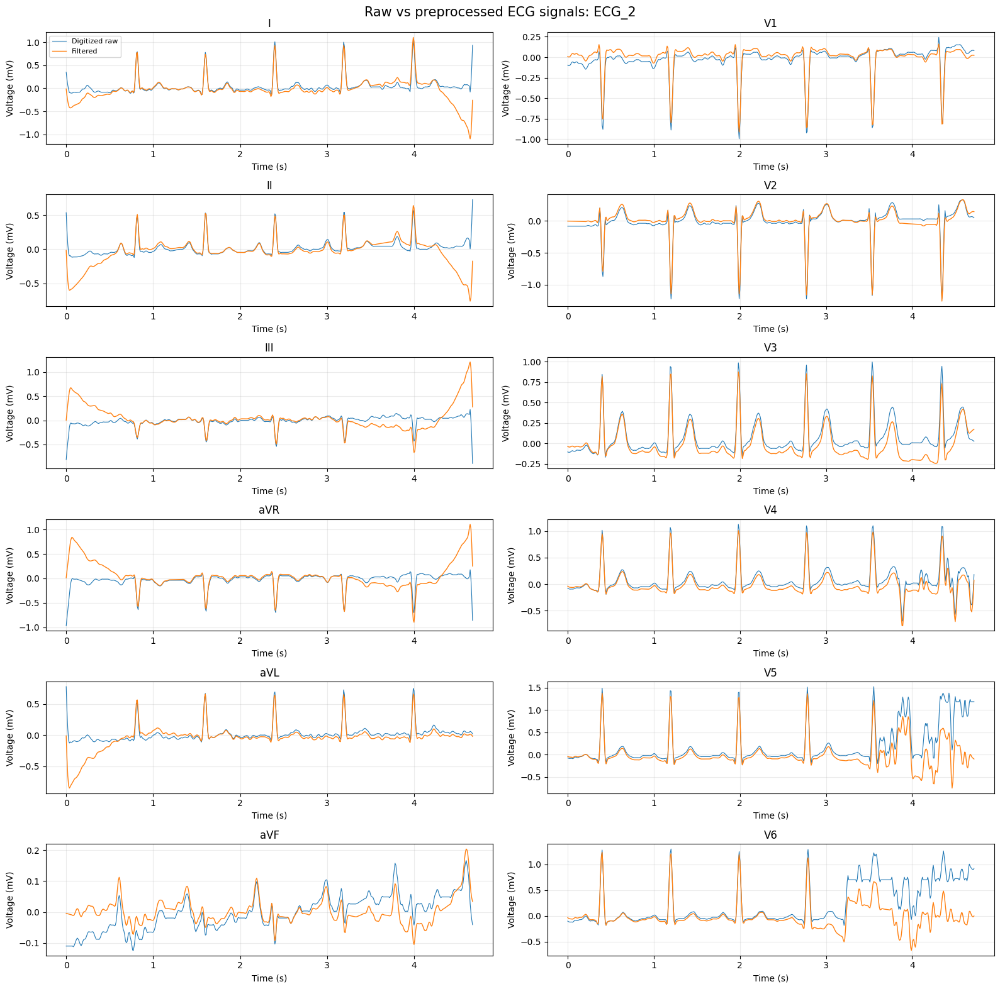

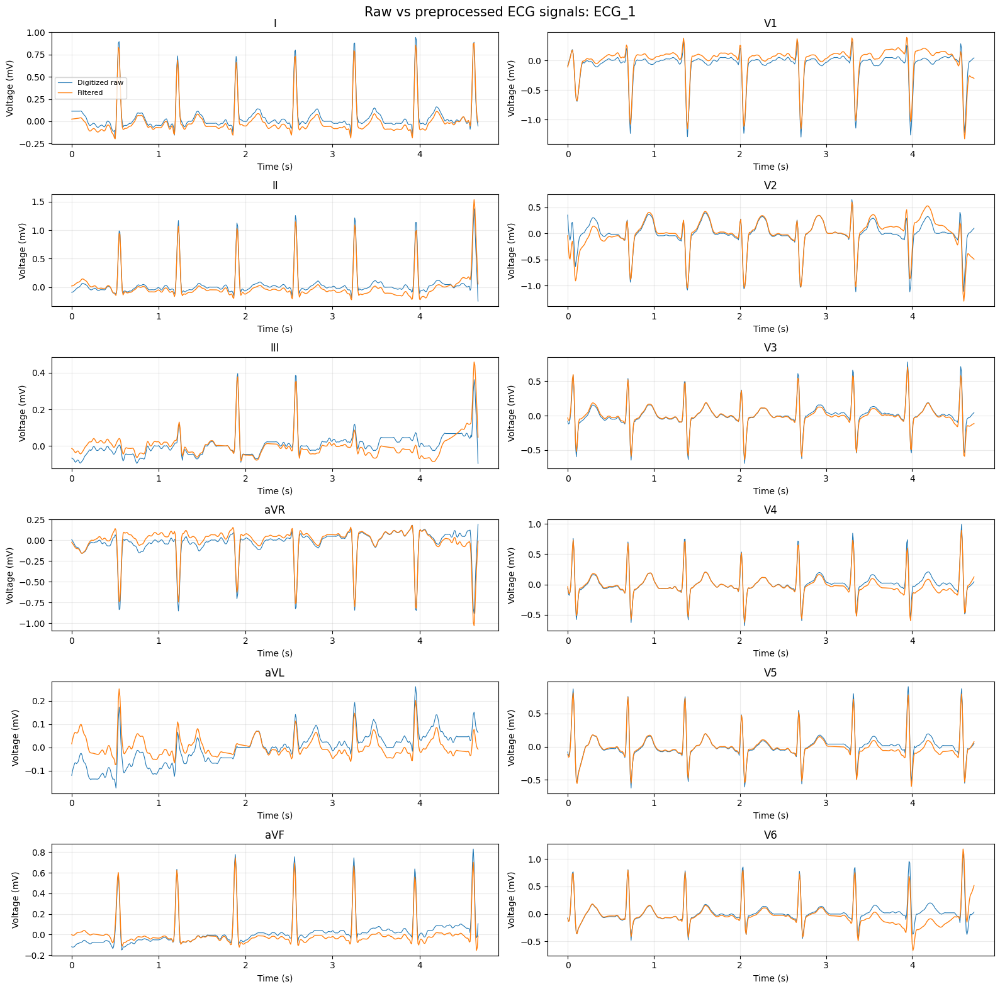

In [20]:
# Cell 8: Plot raw digitized signal vs preprocessed signal for all 12 leads

for record_id, lead_dict in extracted.items():
    fig, axes = plt.subplots(6, 2, figsize=(16, 16), sharex=False)
    for row_idx in range(6):
        for col_idx, lead_name in enumerate([LEFT_LEADS[row_idx], RIGHT_LEADS[row_idx]]):
            d = lead_dict[lead_name]
            ax = axes[row_idx, col_idx]
            ax.plot(d["time_s"], d["raw_mV"], linewidth=0.8, label="Digitized raw")
            ax.plot(d["time_s"], d["filtered_mV"], linewidth=1.0, label="Filtered")
            ax.set_title(lead_name)
            ax.set_xlabel("Time (s)")
            ax.set_ylabel("Voltage (mV)")
            ax.grid(True, alpha=0.25)
            if row_idx == 0 and col_idx == 0:
                ax.legend(fontsize=8)
    fig.suptitle(f"Raw vs preprocessed ECG signals: {record_id}", fontsize=15)
    fig.tight_layout()
    plt.show()
    fig.savefig(OUTPUT_DIR / f"{record_id}_signal_comparison.png", dpi=140, bbox_inches="tight")
    plt.close(fig)

In [21]:
# Cell 9: Save extracted data and summary CSV files

signals_csv = OUTPUT_DIR / "ECG_digitized_and_preprocessed_signals.csv"
summary_csv = OUTPUT_DIR / "ECG_lead_extraction_summary.csv"

signals_df.to_csv(signals_csv, index=False)
summary_df.to_csv(summary_csv, index=False)

print("Saved:", signals_csv)
print("Saved:", summary_csv)
print("Signal data shape:", signals_df.shape)
display(signals_df.head(10))

Saved: ECG_Graph_Data_Processing/ECG_digitized_and_preprocessed_signals.csv
Saved: ECG_Graph_Data_Processing/ECG_lead_extraction_summary.csv
Signal data shape: (12420, 7)


,record_id,lead,sample_index,time_s,voltage_raw_mV,voltage_filtered_mV,voltage_zscore
0,ECG_2,I,0,0.000000,0.347403,-0.016193,0.040023
1,ECG_2,I,1,0.009091,0.191558,-0.159385,-0.539004
2,ECG_2,I,2,0.018182,0.068182,-0.280599,-1.029160
3,ECG_2,I,3,0.027273,-0.022727,-0.367768,-1.381648
4,ECG_2,I,4,0.036364,-0.096320,-0.415176,-1.573351
5,ECG_2,I,5,0.045455,-0.094156,-0.427525,-1.623289
6,ECG_2,I,6,0.054545,-0.106061,-0.422292,-1.602126
7,ECG_2,I,7,0.063636,-0.104978,-0.412688,-1.563289
8,ECG_2,I,8,0.072727,-0.101732,-0.399941,-1.511745
9,ECG_2,I,9,0.081818,-0.090909,-0.384751,-1.450321


In [22]:
# Cell 10: Package all outputs into one ZIP and download
import zipfile

zip_path = Path("ECG_Graph_Data_Processing.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(signals_csv, arcname=signals_csv.name)
    zf.write(summary_csv, arcname=summary_csv.name)
    for p in OUTPUT_DIR.glob("*.png"):
        zf.write(p, arcname=p.name)

print("Created:", zip_path)
files.download(str(zip_path))

Created: ECG_Graph_Data_Processing.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>